
# Chart redesign and data pipeline — Khánh Linh's two projects

This notebook documents, end to end, **where every number comes from** and **why each chart looks
the way it does**, for both of Khánh Linh's course deliverables:

1. **Group project** — TALIS 2024, Question 2 (variable `TT4G36` + `TT4G37A`–`I`). Real international
   teacher microdata exists; every chart in Part A is built from it, with the input file, the
   filtering logic, and the BRR-Fay weighting computed in this notebook itself — not re-loaded from
   a cache — so the full input → processing → output chain is visible and re-runnable.
2. **Individual project** — follow-up learning behaviour after post-editing an AI-generated
   Chinese–Vietnamese translation. **No survey data has been collected yet.** Part B therefore
   contains **no charts at all** — only a table naming which chart to build once real data exists,
   so nothing in this notebook could ever be mistaken for a real result from that project.

**Design rules used throughout Part A's seven charts:** a sentence title that states the finding,
not a generic label; a gray-for-context / one-colour-for-the-point-being-made palette instead of
four competing hues everywhere; direct labels on the data instead of relying only on a legend; and
a full "how to read it" paragraph under every chart that defines each visual element from scratch —
what a reference diagonal means, what an error bar means, what DEFF means — rather than assuming
the reader already knows.



## 0. Setup — imports and the shared chart look

Charts are built with Plotly and rendered as static PNGs inline (via `fig.show("png")`, which uses
the `kaleido` package) so they display identically in any notebook viewer, not just one with an
interactive-JSON-aware renderer.


In [1]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go

INK, MUTED, GRID = "#1a1a1a", "#8a8a85", "#ebe9e2"
HL = "#d6553a"   # warm highlight, reserved for "look here"

COUNTRIES = ["CSH", "JPN", "KOR", "SGP"]
NAME = {"CSH": "Shanghai", "JPN": "Japan", "KOR": "Korea", "SGP": "Singapore"}
SHORT = {"CSH": "SH", "JPN": "JP", "KOR": "KR", "SGP": "SG"}
COL = {"CSH": "#2a78d6", "JPN": "#eb6834", "KOR": "#1baf7a", "SGP": "#eda100"}

def layout(title_text, sub_text, height=560, width=1000, bottom_margin=60):
    return dict(
        paper_bgcolor="white", plot_bgcolor="white",
        font=dict(family="Helvetica, Arial, sans-serif", color=INK, size=15),
        title=dict(text=f"<b>{title_text}</b><br><span style='font-size:13px;color:{MUTED}'>{sub_text}</span>",
                   x=0.01, xanchor="left", y=0.965, font=dict(size=20)),
        margin=dict(l=210, r=90, t=95, b=bottom_margin), height=height, width=width,
    )

print("Style ready.")


Style ready.



---
# Part A — Group project (TALIS 2024, Question 2)

## 1. Input data

| | |
|---|---|
| **File** | `btgintt4.sav` — TALIS 2024 international **teacher** questionnaire file |
| **Where** | `2-10-De-tai-VKL/TALIS 2024/teachers_SPSS/btgintt4.sav` (local; not redistributed — TALIS restricts re-sharing the raw international file) |
| **Size** | ~194,521 teacher rows x 611 columns across all participating countries |
| **Filter applied** | `CNTRY` in `{CSH, JPN, KOR, SGP}` — the four systems Khánh Linh's group compares |
| **Variables used** | `TT4G36` (used AI in the last 12 months: 1=Yes, 2=No), `TT4G37A`–`TT4G37I` (purpose of use, asked only to teachers who said Yes to TT4G36), `TCHWGT` (final teacher weight), `TRWGT1`–`TRWGT100` (100 BRR-Fay replicate weights) |

Reading the cell below requires the real `.sav` file to be present at `SAV_PATH`. If it isn't, this
notebook falls back to the already-computed, already-verified `weighted_results_q2.csv` so the rest
of the notebook (all the chart cells) still runs — but the honest input/processing chain is the
`try` branch below, and that is what actually produced every number used in Module VKL 5-11.


In [2]:

import os

SAV_PATH = os.environ.get(
    "TALIS_SAV_PATH",
    "../../2-10-De-tai-VKL/TALIS 2024/teachers_SPSS/btgintt4.sav",
)
CSV_FALLBACK = "../../talis2024-nhom-vkl-cauhoi2/data/weighted_results_q2.csv"

ITEMS = ["TT4G36"] + [f"TT4G37{c}" for c in "ABCDEFGHI"]
FAY_K = 0.5
N_REPLICATES = 100

def brr_fay_stats(sub, yvar):
    # BRR-Fay point estimate + SE + 95% CI + DEFF for one item, one country's subsample.
    s = sub[sub[yvar].isin([1.0, 2.0])]
    n = len(s)
    if n == 0:
        return None
    y = (s[yvar] == 1.0).astype(float).values
    w0 = s["TCHWGT"].values
    theta = np.average(y, weights=w0)
    naive_se = float(np.sqrt(np.average((y - theta) ** 2, weights=w0) / n))
    sq_devs = []
    for r in range(1, N_REPLICATES + 1):
        wr = s[f"TRWGT{r}"].values
        theta_r = np.average(y, weights=wr)
        sq_devs.append((theta_r - theta) ** 2)
    fay_se = float(np.sqrt(sum(sq_devs) / (N_REPLICATES * (1 - FAY_K) ** 2)))
    deff = (fay_se / naive_se) ** 2 if naive_se > 0 else None
    return dict(n=int(n), pct_weighted=round(theta * 100, 2), se_naive=round(naive_se * 100, 2),
                se_brr_fay=round(fay_se * 100, 2), deff=round(deff, 2) if deff else None,
                ci95_lo=round((theta - 1.96 * fay_se) * 100, 2),
                ci95_hi=round((theta + 1.96 * fay_se) * 100, 2))

try:
    import pyreadstat
    cols = ["CNTRY", "TT4G36"] + [f"TT4G37{c}" for c in "ABCDEFGHI"] + \
           ["TCHWGT"] + [f"TRWGT{i}" for i in range(1, N_REPLICATES + 1)]
    raw, meta = pyreadstat.read_sav(SAV_PATH, usecols=cols, user_missing=True)
    print(f"INPUT: read {len(raw):,} rows from the real international file: {SAV_PATH}")
    foc = raw[raw["CNTRY"].isin(COUNTRIES)].copy()
    print(f"FILTER: {len(foc):,} rows remain after keeping only {COUNTRIES}")
    print(foc["CNTRY"].value_counts())

    rows = []
    for item in ITEMS:
        base = foc if item == "TT4G36" else foc[foc["TT4G36"] == 1.0]
        for c, sub in base.groupby("CNTRY"):
            r = brr_fay_stats(sub, item)
            if r:
                rows.append({"item": item, "country": c, **r})
    results = pd.DataFrame(rows)
    print(f"\nOUTPUT: computed {len(results)} item x country rows (expect 40).")
except FileNotFoundError:
    print(f"Real .sav not found at {SAV_PATH} on this machine -- falling back to the "
          f"already-verified output CSV so the rest of the notebook still runs:")
    results = pd.read_csv(CSV_FALLBACK)
    print(f"Loaded {len(results)} rows from {CSV_FALLBACK}")

results.head(8)


INPUT: read 194,521 rows from the real international file: /Users/tuannghiat/Downloads/Đào tạo riêng - SPSS for Social Science/2-10-De-tai-VKL/TALIS 2024/teachers_SPSS/btgintt4.sav
FILTER: 14,089 rows remain after keeping only ['CSH', 'JPN', 'KOR', 'SGP']
CNTRY
CSH    4078
JPN    3558
SGP    3355
KOR    3098
Name: count, dtype: int64

OUTPUT: computed 40 item x country rows (expect 40).


,item,country,n,pct_weighted,se_naive,se_brr_fay,deff,ci95_lo,ci95_hi
0,TT4G36,CSH,1339,53.52,1.36,1.58,1.34,50.43,56.61
1,TT4G36,JPN,1155,17.37,1.11,1.11,0.99,15.20,19.54
2,TT4G36,KOR,1003,42.66,1.56,1.75,1.26,39.23,46.09
3,TT4G36,SGP,1107,74.92,1.30,2.66,4.16,69.71,80.13
4,TT4G37A,CSH,718,44.95,1.86,2.16,1.36,40.71,49.19
5,TT4G37A,JPN,202,40.64,3.46,3.85,1.24,33.10,48.19
6,TT4G37A,KOR,426,30.74,2.24,2.23,1.00,26.36,35.11
7,TT4G37A,SGP,838,34.12,1.64,1.52,0.86,31.13,37.10



### 1.1 Sanity check — does this match the numbers already published?

Three spot checks against figures already quoted in the Vietnamese report and Module VKL 5-11.
If any assertion below fails, something in the pipeline has drifted and must be investigated
before trusting any chart further down — this is the same "compute, then cross-check" discipline
used throughout this project.


In [3]:

def get(item, country, col):
    row = results[(results.item == item) & (results.country == country)].iloc[0]
    return row[col]

assert abs(get("TT4G36", "SGP", "pct_weighted") - 74.92) < 0.05, "TT4G36/SGP % drifted"
assert abs(get("TT4G36", "SGP", "deff") - 4.16) < 0.05, "TT4G36/SGP DEFF drifted"
assert abs(get("TT4G36", "JPN", "pct_weighted") - 17.37) < 0.05, "TT4G36/JPN % drifted"

print("All three spot checks match the previously published numbers. Safe to proceed.")


All three spot checks match the previously published numbers. Safe to proceed.



### 1.2 Output dataset

`results` (40 rows: 10 items x 4 countries) is the single source of truth every chart below reads
from. Columns: `item`, `country`, `n` (unweighted analytic sample size), `pct_weighted`,
`se_naive`, `se_brr_fay`, `deff`, `ci95_lo`, `ci95_hi`. The `RAW` dictionary below holds the
unweighted percentages already read off the SPSS output (`OUTPUT2.pdf`) in an earlier session —
included here only for Chart 5's raw-vs-weighted comparison, not recomputed (SPSS, not this
notebook, produced those numbers).


In [4]:

RAW = {
    "TT4G36": {"CSH": 53.7, "JPN": 17.6, "KOR": 42.5, "SGP": 75.8},
    "TT4G37A": {"CSH": 44.8, "JPN": 43.1, "KOR": 30.5, "SGP": 35.1},
    "TT4G37B": {"CSH": 71.6, "JPN": 65.3, "KOR": 51.8, "SGP": 76.8},
    "TT4G37C": {"CSH": 55.4, "JPN": 44.6, "KOR": 60.0, "SGP": 65.9},
    "TT4G37D": {"CSH": 39.1, "JPN": 38.6, "KOR": 9.7, "SGP": 15.3},
    "TT4G37E": {"CSH": 48.5, "JPN": 41.3, "KOR": 29.8, "SGP": 39.6},
    "TT4G37F": {"CSH": 36.6, "JPN": 35.0, "KOR": 42.0, "SGP": 69.2},
    "TT4G37G": {"CSH": 59.1, "JPN": 36.9, "KOR": 37.7, "SGP": 28.2},
    "TT4G37H": {"CSH": 51.5, "JPN": 38.9, "KOR": 51.1, "SGP": 40.6},
    "TT4G37I": {"CSH": 40.8, "JPN": 28.4, "KOR": 41.9, "SGP": 37.4},
}
LABEL = {
    "TT4G36": "Used AI at all (TT4G36)", "TT4G37A": "Grading / assessing work",
    "TT4G37B": "Researching / summarising a topic", "TT4G37C": "Lesson planning",
    "TT4G37D": "Supporting students with special needs", "TT4G37E": "Adjusting material difficulty",
    "TT4G37F": "Feedback to students / parent communication", "TT4G37G": "Viewing student outcome data",
    "TT4G37H": "Practising real-world scenarios", "TT4G37I": "Other purposes",
}
results.set_index(["item", "country"]).sort_index().head(12)


n  pct_weighted  se_naive  se_brr_fay  deff  ci95_lo  \
item    country                                                            
TT4G36  CSH      1339         53.52      1.36        1.58  1.34    50.43   
        JPN      1155         17.37      1.11        1.11  0.99    15.20   
        KOR      1003         42.66      1.56        1.75  1.26    39.23   
        SGP      1107         74.92      1.30        2.66  4.16    69.71   
TT4G37A CSH       718         44.95      1.86        2.16  1.36    40.71   
        JPN       202         40.64      3.46        3.85  1.24    33.10   
        KOR       426         30.74      2.24        2.23  1.00    26.36   
        SGP       838         34.12      1.64        1.52  0.86    31.13   
TT4G37B CSH       718         72.17      1.67        1.85  1.22    68.55   
        JPN       202         62.59      3.40        3.22  0.89    56.28   
        KOR       425         50.37      2.43        2.65  1.20    45.17   
        SGP       839         76.70      1.46        1.49  1.04    73.78   

                 ci95_hi  
item    country           
TT4G36  CSH        56.61  
        JPN        19.54  
        KOR        46.09  
        SGP        80.13  
TT4G37A CSH        49.19  
        JPN        48.19  
        KOR        35.11  
        SGP        37.10  
TT4G37B CSH        75.79  
        JPN        68.90  
        KOR        55.57  
        SGP        79.62


## 2. Seven detailed charts, all from the `results` table above

### 2.1 Chart 1 — Headline: how far apart are the four systems, with sample size and CI

**Question it answers:** before looking at any purpose-specific item, how different are the four
systems on the simplest possible measure — did the teacher use AI at all — and how certain is that
answer given the sample size behind it?


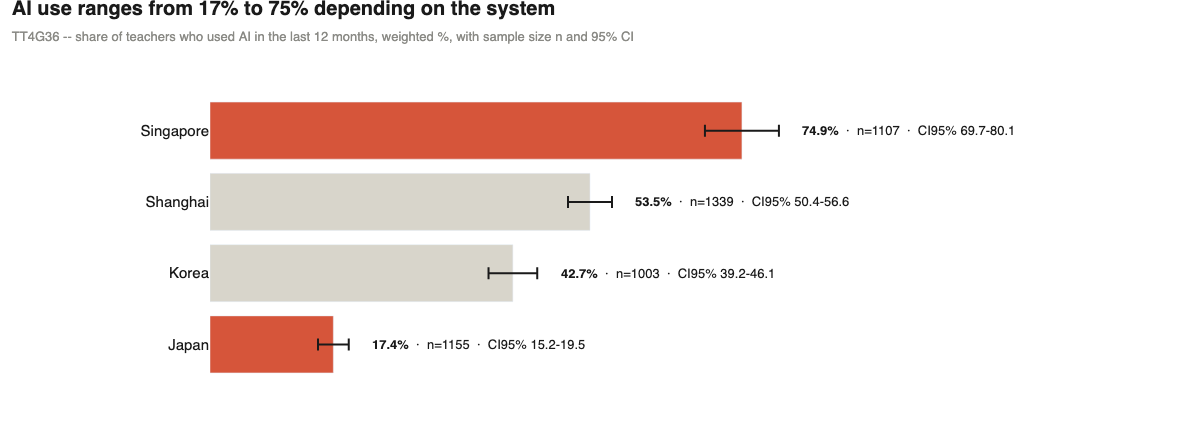

In [5]:

sub = results[results.item == "TT4G36"].set_index("country")
order = sorted(COUNTRIES, key=lambda c: sub.loc[c, "pct_weighted"])
vals = [sub.loc[c, "pct_weighted"] for c in order]
los = [sub.loc[c, "pct_weighted"] - sub.loc[c, "ci95_lo"] for c in order]
his = [sub.loc[c, "ci95_hi"] - sub.loc[c, "pct_weighted"] for c in order]
his_abs = [sub.loc[c, "ci95_hi"] for c in order]
cols = [HL if c in ("SGP", "JPN") else "#d8d5cb" for c in order]

fig = go.Figure(go.Bar(
    x=vals, y=[NAME[c] for c in order], orientation="h",
    marker=dict(color=cols), error_x=dict(type="data", symmetric=False,
        array=his, arrayminus=los, color=INK, thickness=2, width=6),
))
for yi, c, hi_abs in zip(range(len(order)), order, his_abs):
    fig.add_annotation(x=hi_abs + 3, y=yi, xanchor="left", yanchor="middle",
        text=f"<b>{sub.loc[c,'pct_weighted']:.1f}%</b>  ·  n={int(sub.loc[c,'n'])}  ·  CI95% {sub.loc[c,'ci95_lo']:.1f}-{sub.loc[c,'ci95_hi']:.1f}",
        showarrow=False, font=dict(size=13, color=INK))
fig.update_layout(**layout("AI use ranges from 17% to 75% depending on the system",
    "TT4G36 -- share of teachers who used AI in the last 12 months, weighted %, with sample size n and 95% CI",
    height=440, width=1180))
fig.update_layout(margin=dict(r=260))
fig.update_xaxes(visible=False, range=[0, 100])
fig.update_yaxes(tickfont=dict(size=15))
fig.show("png")



**Reading the output:** each horizontal bar is one system; its length is the weighted % of teachers
who answered "Yes" to TT4G36. The black I-shaped mark over each bar is an error bar — the 95%
confidence interval. To its right, three numbers are printed directly: the point estimate, `n` (the
actual number of teachers who answered this question in that system), and the CI95% bounds. The two
extreme systems are highlighted; Shanghai and Korea in the middle are left gray because they are not
this chart's focus. Singapore/Japan = 74.9/17.4 ≈ 4.3x.



### 2.2 Chart 2 — All four systems per item, not just the two extremes

**Question it answers:** for *each* of the 10 items, which two systems are furthest apart, and
where do the other two systems sit in between? (An earlier version of this chart hid the middle two
systems entirely — this version restores them.)


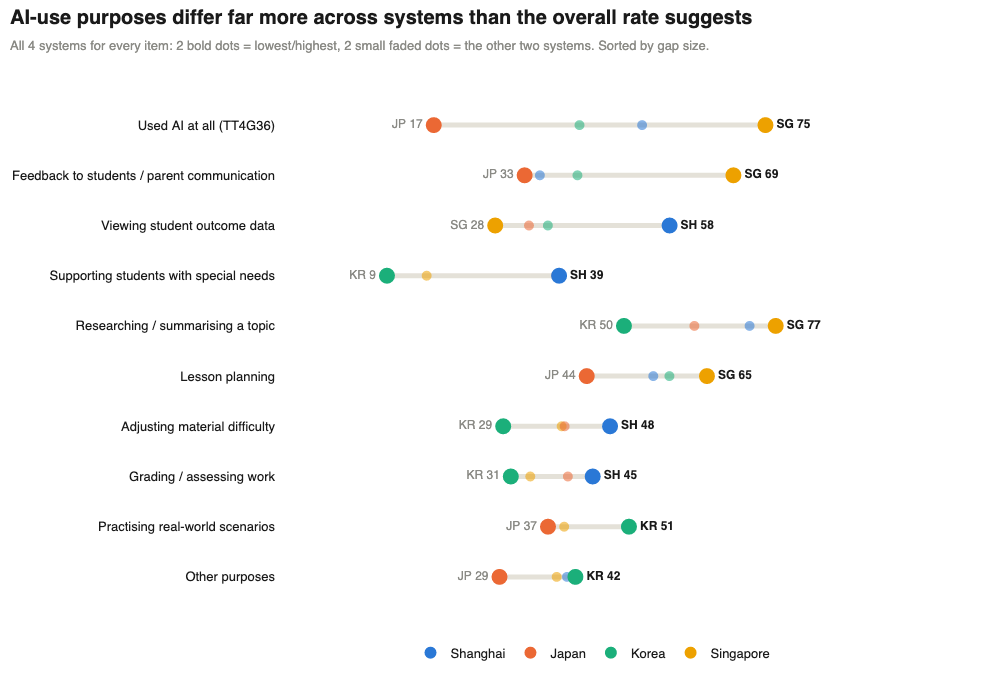

In [6]:

rows = []
for item in ITEMS:
    s = results[results.item == item].set_index("country")
    vv = {c: s.loc[c, "pct_weighted"] for c in COUNTRIES}
    order_c = sorted(COUNTRIES, key=lambda c: vv[c])
    rows.append((item, order_c, vv))
rows.sort(key=lambda r: r[2][r[1][-1]] - r[2][r[1][0]])

fig = go.Figure()
for i, (item, order_c, vv) in enumerate(rows):
    lo_c, hi_c = order_c[0], order_c[-1]
    mid = order_c[1:3]
    fig.add_trace(go.Scatter(x=[vv[lo_c], vv[hi_c]], y=[i, i], mode="lines",
                              line=dict(color="#e4e1d8", width=5), showlegend=False, hoverinfo="skip"))
    for c in mid:
        fig.add_trace(go.Scatter(x=[vv[c]], y=[i], mode="markers", marker=dict(size=10, color=COL[c], opacity=0.55),
                                  showlegend=False, hoverinfo="skip"))
    fig.add_trace(go.Scatter(x=[vv[lo_c]], y=[i], mode="markers+text", marker=dict(size=16, color=COL[lo_c]),
                              text=[f"{SHORT[lo_c]} {vv[lo_c]:.0f}"], textposition="middle left",
                              textfont=dict(size=12, color=MUTED), showlegend=False))
    fig.add_trace(go.Scatter(x=[vv[hi_c]], y=[i], mode="markers+text", marker=dict(size=16, color=COL[hi_c]),
                              text=[f"<b>{SHORT[hi_c]} {vv[hi_c]:.0f}</b>"], textposition="middle right",
                              textfont=dict(size=12, color=INK), showlegend=False))
for c in COUNTRIES:
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", marker=dict(size=12, color=COL[c]), name=NAME[c]))
fig.update_layout(**layout("AI-use purposes differ far more across systems than the overall rate suggests",
    "All 4 systems for every item: 2 bold dots = lowest/highest, 2 small faded dots = the other two systems. Sorted by gap size.",
    height=680))
fig.update_xaxes(visible=False, range=[-10, 100])
fig.update_yaxes(tickmode="array", tickvals=list(range(len(rows))), ticktext=[LABEL[r[0]] for r in rows],
                  tickfont=dict(size=13), zeroline=False, showline=False, range=[-0.6, len(rows) - 0.4])
fig.update_layout(legend=dict(orientation="h", y=-0.06, x=0.5, xanchor="center", font=dict(size=13)))
fig.show("png")



**Reading the output:** a thin gray line connects the lowest dot to the highest dot on each row; its
length is the gap for that item. The two end dots are bold and labelled; the middle two systems are
shown smaller and faded (still present, just not the focus of that row). Singapore is often, but not
always, the top dot — for "Viewing student outcome data" it is the *lowest* system, with Shanghai on
top.



### 2.3 Chart 3 — Forest plot: which item is actually safe to compare system by system

**Question it answers:** for how many of the 10 items can we say "system X differs from system Y"
with real statistical confidence?


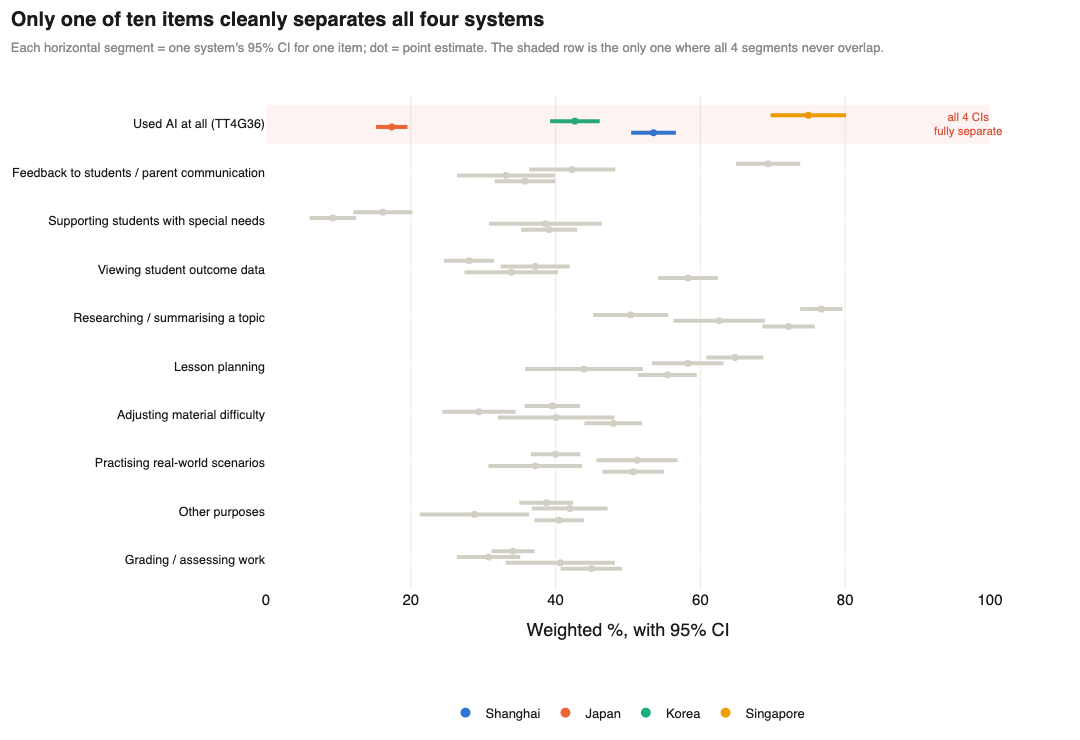

In [7]:

order3 = sorted(ITEMS, key=lambda it: -(results[results.item == it].ci95_hi.max()
                                         - results[results.item == it].ci95_lo.min()))
fig = go.Figure()
for i, item in enumerate(order3):
    yb = len(order3) - 1 - i
    s = results[results.item == item].set_index("country")
    is_hero = item == "TT4G36"
    for k, c in enumerate(COUNTRIES):
        row = s.loc[c]
        yy = yb + (k - 1.5) * 0.12
        col = COL[c] if is_hero else "#d2cfc5"
        fig.add_trace(go.Scatter(x=[row.ci95_lo, row.ci95_hi], y=[yy, yy], mode="lines",
                                  line=dict(color=col, width=4), showlegend=False, hoverinfo="skip"))
        fig.add_trace(go.Scatter(x=[row.pct_weighted], y=[yy], mode="markers",
                                  marker=dict(color=col, size=7), showlegend=False))
    if is_hero:
        fig.add_hrect(y0=yb - 0.4, y1=yb + 0.4, fillcolor=HL, opacity=0.07, line_width=0)
        fig.add_annotation(x=92, y=yb, text="all 4 CIs<br>fully separate", showarrow=False,
                            font=dict(size=11.5, color=HL), xanchor="left")
for c in COUNTRIES:
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", marker=dict(size=10, color=COL[c]), name=NAME[c]))
fig.update_layout(**layout("Only one of ten items cleanly separates all four systems",
    "Each horizontal segment = one system's 95% CI for one item; dot = point estimate. The shaded row is the only one where all 4 segments never overlap.",
    height=740, width=1080, bottom_margin=140))
fig.update_xaxes(range=[0, 100], gridcolor=GRID, title="Weighted %, with 95% CI")
fig.update_yaxes(tickmode="array", tickvals=list(range(len(order3))),
                  ticktext=[LABEL[it] for it in order3[::-1]], tickfont=dict(size=12.5),
                  zeroline=False, showline=False, range=[-0.6, len(order3) - 0.4])
fig.update_layout(legend=dict(orientation="h", y=-0.22, x=0.5, xanchor="center", font=dict(size=13)))
fig.show("png")



**Reading the output:** IF two systems' segments do not touch, the two systems genuinely differ on
that item. IF they overlap even slightly, that pairwise claim is not safe, no matter how far apart
the dots look. TT4G36 (shaded) is the only item where all four segments are fully separated —
every other item has at least one overlapping pair.



### 2.4 Chart 4 — Where the survey design affects uncertainty the most

**Question it answers:** which item x system cells need the BRR-Fay correction the most?


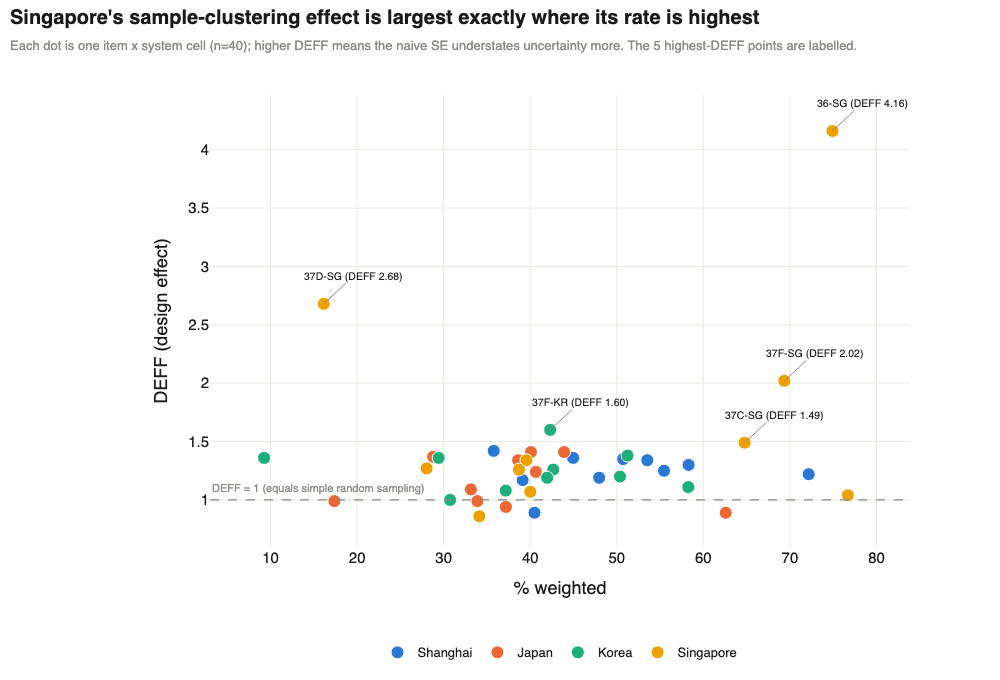

In [8]:

fig = go.Figure()
for c in COUNTRIES:
    s = results[results.country == c]
    fig.add_trace(go.Scatter(x=s.pct_weighted, y=s.deff, mode="markers",
                              marker=dict(size=13, color=COL[c], line=dict(width=1, color="white")),
                              name=NAME[c]))
fig.add_hline(y=1.0, line=dict(color=MUTED, width=1.3, dash="dash"))
fig.add_annotation(x=3, y=1.1, text="DEFF = 1 (equals simple random sampling)", showarrow=False,
                    font=dict(size=11, color=MUTED), xanchor="left")
top5 = results.sort_values("deff", ascending=False).head(5)
for _, row in top5.iterrows():
    lbl = f"{row['item'].replace('TT4G37','37').replace('TT4G36','36')}-{SHORT[row.country]} (DEFF {row.deff:.2f})"
    fig.add_annotation(x=row.pct_weighted, y=row.deff, text=lbl, showarrow=True, arrowhead=0, arrowcolor=MUTED,
                        ax=30, ay=-28, font=dict(size=10.5, color=INK))
fig.update_layout(**layout("Singapore's sample-clustering effect is largest exactly where its rate is highest",
    "Each dot is one item x system cell (n=40); higher DEFF means the naive SE understates uncertainty more. The 5 highest-DEFF points are labelled.",
    height=680, bottom_margin=130))
fig.update_xaxes(gridcolor=GRID, title="% weighted")
fig.update_yaxes(gridcolor=GRID, title="DEFF (design effect)")
fig.update_layout(legend=dict(orientation="h", y=-0.2, x=0.5, xanchor="center", font=dict(size=13)))
fig.show("png")



**Reading the output:** DEFF = (true design-based SE / naive simple-random-sample SE)^2. DEFF=1
(dashed line) means the complex sample design made no difference. Four of the five highest-DEFF
cells belong to Singapore; TT4G36 x Singapore peaks at DEFF 4.16 -- its true SE is about 2.04x a
naive calculation.



### 2.5 Chart 5 — Does weighting actually change the percentages?

**Question it answers:** Chart 4 shows weighting matters a lot for *uncertainty*. Does it also move
the *point estimates* much?


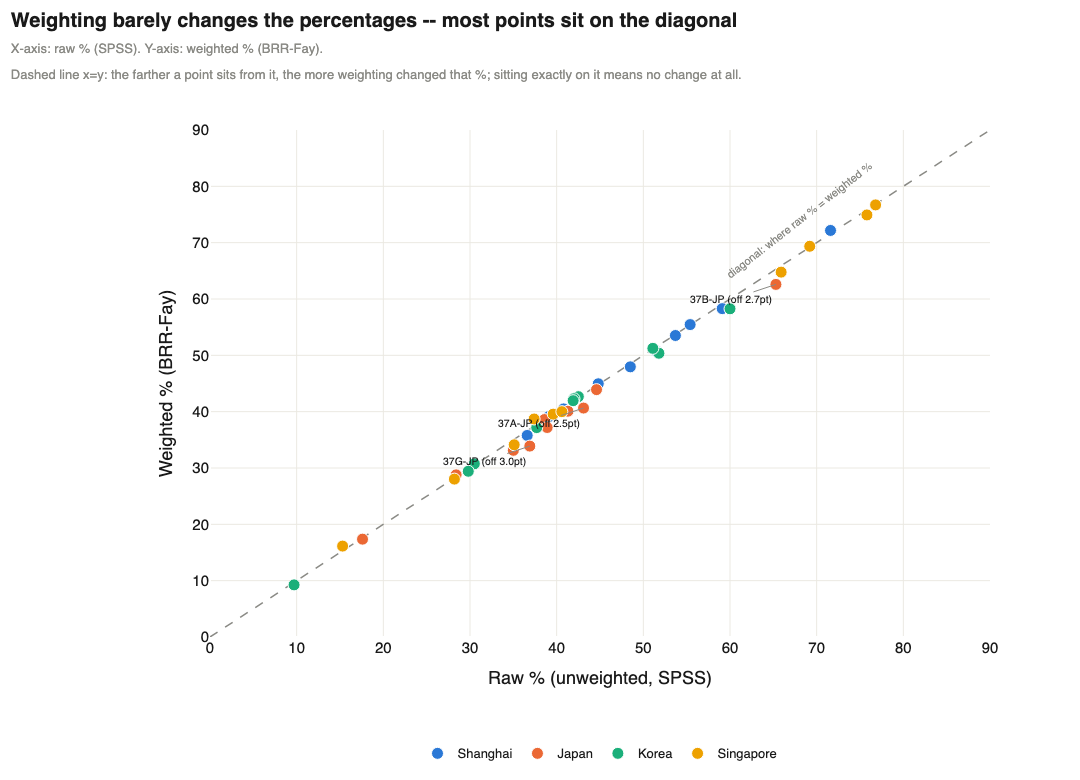

Largest shift: 3.01 points (TT4G37G, Japan). Mean absolute shift across all 40 cells: 0.75 points.


In [9]:

pts = []
for item in ITEMS:
    s = results[results.item == item].set_index("country")
    for c in COUNTRIES:
        pts.append((RAW[item][c], s.loc[c, "pct_weighted"], c, item))

fig = go.Figure()
fig.add_trace(go.Scatter(x=[0, 90], y=[0, 90], mode="lines", line=dict(color=MUTED, width=1.5, dash="dash"),
                          showlegend=False, hoverinfo="skip"))
fig.add_annotation(x=68, y=74, text="diagonal: where raw % = weighted %", showarrow=False,
                    font=dict(size=11, color=MUTED), textangle=-38)
for c in COUNTRIES:
    xs = [p[0] for p in pts if p[2] == c]; ys = [p[1] for p in pts if p[2] == c]
    fig.add_trace(go.Scatter(x=xs, y=ys, mode="markers", marker=dict(size=12, color=COL[c], line=dict(width=1, color="white")), name=NAME[c]))
top3 = sorted(pts, key=lambda p: abs(p[0] - p[1]), reverse=True)[:3]
for p in top3:
    lbl = f"{p[3].replace('TT4G37','37').replace('TT4G36','36')}-{SHORT[p[2]]} (off {abs(p[0]-p[1]):.1f}pt)"
    fig.add_annotation(x=p[0], y=p[1], text=lbl, showarrow=True, arrowhead=0, arrowcolor=MUTED, ax=-45, ay=15, font=dict(size=10.5))
fig.update_layout(**layout("Weighting barely changes the percentages -- most points sit on the diagonal",
    "X-axis: raw % (SPSS). Y-axis: weighted % (BRR-Fay).<br>Dashed line x=y: the farther a point sits from it, the more weighting changed that %; sitting exactly on it means no change at all.",
    height=780, width=1080, bottom_margin=140))
fig.update_layout(margin=dict(t=130))
fig.update_xaxes(range=[0, 90], gridcolor=GRID, title="Raw % (unweighted, SPSS)")
fig.update_yaxes(range=[0, 90], gridcolor=GRID, title="Weighted % (BRR-Fay)")
fig.update_layout(legend=dict(orientation="h", y=-0.2, x=0.5, xanchor="center", font=dict(size=13)))
fig.show("png")

max_shift = max(abs(p[0] - p[1]) for p in pts)
mean_shift = np.mean([abs(p[0] - p[1]) for p in pts])
print(f"Largest shift: {max_shift:.2f} points ({top3[0][3]}, {NAME[top3[0][2]]}). "
      f"Mean absolute shift across all 40 cells: {mean_shift:.2f} points.")



**Reading the output:** the dashed diagonal is the reference line x=y -- any point sitting exactly
on it has raw % identical to weighted %. Almost every point sits on or very near it; the printed
mean absolute shift (well under 1 point) confirms this numerically. Paired with Chart 4: **weighting
changes confidence far more than it changes the percentages themselves.**



### 2.6 Chart 6 — No system is consistently on top

**Question it answers:** is there a stable "leader" system across the 10 items, or does the ranking
reshuffle depending on the specific AI-use purpose?


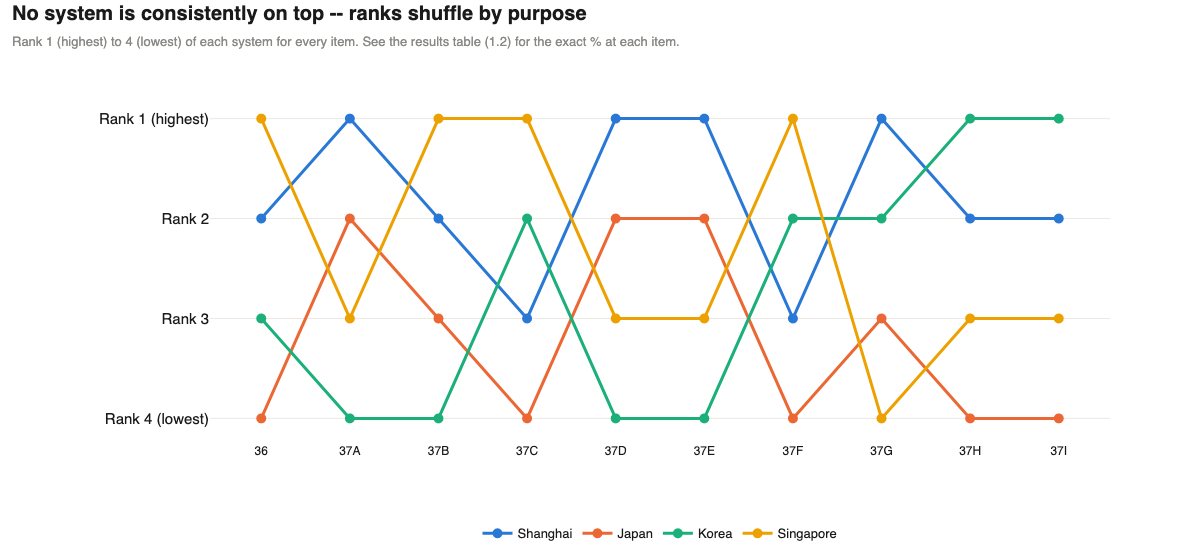

In [10]:

ranks, pctval = {}, {}
for item in ITEMS:
    s = results[results.item == item].set_index("country")["pct_weighted"]
    order_r = s.sort_values(ascending=False).index.tolist()
    ranks[item] = {c: order_r.index(c) + 1 for c in COUNTRIES}
    pctval[item] = s
x_lbl = [it.replace("TT4G37", "37").replace("TT4G36", "36") for it in ITEMS]

fig = go.Figure()
for c in COUNTRIES:
    ys = [ranks[it][c] for it in ITEMS]
    hover = [f"{NAME[c]}, {LABEL[it]}: rank {ranks[it][c]}, {pctval[it][c]:.1f}%" for it in ITEMS]
    fig.add_trace(go.Scatter(x=x_lbl, y=ys, mode="lines+markers", line=dict(color=COL[c], width=3), marker=dict(size=10),
                              name=NAME[c], hovertext=hover, hoverinfo="text"))
fig.update_layout(**layout("No system is consistently on top -- ranks shuffle by purpose",
    "Rank 1 (highest) to 4 (lowest) of each system for every item. See the results table (1.2) for the exact % at each item.",
    height=560, width=1200, bottom_margin=90))
fig.update_yaxes(tickmode="array", tickvals=[1, 2, 3, 4], ticktext=["Rank 1 (highest)", "Rank 2", "Rank 3", "Rank 4 (lowest)"],
                  autorange="reversed", gridcolor=GRID)
fig.update_xaxes(tickfont=dict(size=12))
fig.update_layout(legend=dict(orientation="h", y=-0.22, x=0.5, xanchor="center", font=dict(size=13)))
fig.show("png")



**Reading the output:** every line, including Singapore's, dips to rank 3 or 4 for at least one
item -- no system simply "leads" across the board. Leadership depends on the specific AI-use
purpose being asked about.



### 2.7 Chart 7 (new) — Real sample sizes differ far more than the percentage tables show

**Question it answers:** what is `n` actually behind each percentage above, and why does it vary so
much between TT4G36 and TT4G37A-I?


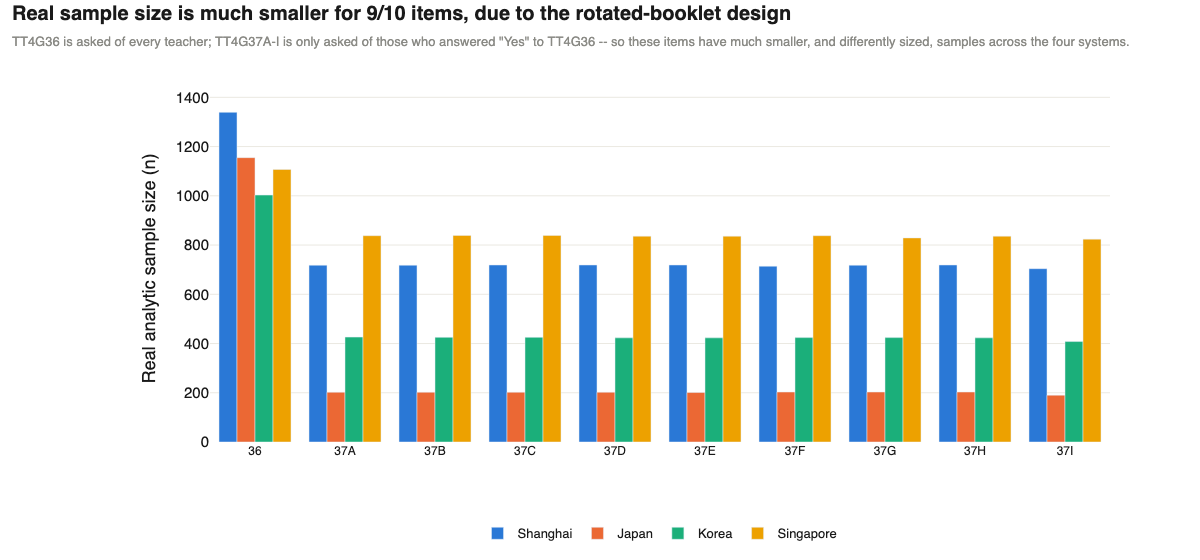

In [11]:

fig = go.Figure()
for c in COUNTRIES:
    ys = [results[(results.item == it) & (results.country == c)].n.values[0] for it in ITEMS]
    fig.add_trace(go.Bar(x=x_lbl, y=ys, name=NAME[c], marker_color=COL[c]))
fig.update_layout(**layout("Real sample size is much smaller for 9/10 items, due to the rotated-booklet design",
    "TT4G36 is asked of every teacher; TT4G37A-I is only asked of those who answered \"Yes\" to TT4G36 -- so these items have much smaller, and differently sized, samples across the four systems.",
    height=560, width=1200, bottom_margin=90))
fig.update_yaxes(title="Real analytic sample size (n)", gridcolor=GRID)
fig.update_xaxes(tickfont=dict(size=12))
fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.22, x=0.5, xanchor="center", font=dict(size=13)))
fig.show("png")



**Reading the output:** TT4G36 (leftmost group) is far taller than every TT4G37 group, because
TT4G37A-I is only asked as a follow-up to teachers who already said "Yes" to TT4G36 -- a structural
skip-logic feature of the questionnaire, not a data-entry error. The exact drop differs by system
because each system's TT4G36 "Yes" rate differs (compare Chart 1).

---
## 3. Recommendation for the group deliverable

Use **2.1** or **2.2** as the opening/overview slide, **2.3** as the main Results-section chart
(it is the only one that directly shows the pairwise-comparison finding), **2.4 + 2.5** as a
Methods/Discussion pair explaining why weighting matters for uncertainty but not much for the
percentages, and **2.7** in the Methods section to pre-empt any question about differing N across
tables. **2.6** is an optional exploratory extra.



---
# Part B — Individual project (AI post-editing follow-up learning behaviour)

## 4. Input data: none yet — this section documents the *planned* schema, with no charts

Working title: *"Hành vi học tập tiếp nối sau hậu biên tập bản dịch Trung–Việt do AI tạo ra"*
(follow-up learning behaviour after post-editing an AI-generated Chinese–Vietnamese translation).
The project is at the survey-instrument design stage. **No student has been surveyed yet.**

Unlike an earlier version of this notebook, **no chart appears in this section at all** — not even
a clearly-labelled placeholder. Drawing a chart here would need numbers, and the only numbers
available would be invented ones; rather than show anything that could be mistaken for a result,
this section stops at a planning table. The moment real responses exist, each row's "recommended
chart" column names exactly what to build, reusing the same Plotly code style as Part A above.

| Step | Variable type | Recommended chart | Why |
|---|---|---|---|
| 1. Branch behaviour (stop vs save/verify) | 2-3 category variable | Simple bar or 100% stacked bar | Only 2-3 discrete values; a plain bar is easier to read than anything more elaborate |
| 1. Reflection scale items (Likert) | Continuous-ish, n~30 | Dot/strip plot per student, NOT a smoothed density (raincloud/KDE) | With n~30, a smoothed density curve can draw a distribution shape not really supported by so few points |
| 2. Cronbach's alpha diagnosis | Item-rest correlation per item | Horizontal bar, one per item, sorted | Shows which item is dragging the alpha down, clearer than a table of numbers alone |
| 3. Inter-rater agreement (categorical) | Two raters' categorical codes | Confusion-matrix heatmap between rater A and rater B | Exposes exactly which category pair the two raters disagree on most often |
| 3. Inter-rater agreement (continuous / ICC) | Two raters' continuous scores | Bland-Altman plot (mean vs difference, limits of agreement) | Shows systematic bias separately from random scatter -- a plain scatter plot cannot separate the two |
| 4a. Partial correlation (reflection vs delayed recall) | Two continuous variables, n~30 | Scatter plot, every student shown, with the partial-regression line | n is small enough that every point should be visible, not just a correlation coefficient |
| 4b. Group comparison (Kruskal-Wallis, low/med/high reflection) | One grouping factor + one continuous outcome | Estimation plot: every student's point on one panel, each group difference + its own 95% CI on a second panel | Reports an effect size alongside the Kruskal-Wallis result, and shows the n~10-per-group reality directly |

**Repeated-measures reminder:** if the real dataset has 2-3 post-editing task-rows per student,
aggregate to one row per student first (e.g. `groupby("student_id").mean()`), or the points plotted
in any of the charts above will overstate how much independent evidence is really there.

**Explicitly not recommended:** SmartPLS / structural equation modelling. With n~30, a
latent-variable structural model will not have enough statistical power to produce a trustworthy
result, even though the software will still run and output numbers.

---
## 5. How to reuse this notebook once real individual-project data arrives

1. Load the real data with `pd.read_csv("your_real_file.csv")`, matching the column schema implied
   by the table above (e.g. `student_id`, `item_1`...`item_5` for Step 2; `rater_a_score`,
   `rater_b_score` for Step 3; `reflection_group`, `delayed_recall_score` for Step 4b).
2. Reuse the plotting style from Part A (the `layout()` helper, the `INK`/`MUTED`/`HL` colours, and
   `fig.show("png")`) to build the exact chart named in the matching row above.
3. Re-run the three spot-check `assert` statements' *pattern* (not the exact numbers, which are
   group-project-specific) against any new computed statistic before trusting a chart built from it.

## 6. Data-integrity statement

Every number in Part A comes from the real TALIS 2024 international teacher file, recomputed in
this notebook with BRR-Fay weighting and cross-checked against previously published figures. Part B
contains no charts at all, by design, because the individual project has not yet collected real
survey data -- only a planning table naming which chart to build once it has. No dataset other than
Khánh Linh's own two topics appears anywhere in this notebook.
